# EP2 · Fórmula 1 (2020–2026): modelos, decisiones e insights

**Asignatura:** MACHINE LEARNING_001V · Evaluación Parcial 2
**Grupo:** Christian Tapia · Claudio Iribarne · Diego Cortés · Mario Escobar

**Datos:** temporadas **2020–2026** de Fórmula 1, en el mismo formato de tablas Ergast que el dataset [Formula 1 Race Data (Kaggle)](https://www.kaggle.com/datasets/cjgdev/formula-1-race-data-19502017) y que usa el notebook [F1 Race Traces 2026 (Kaggle)](https://www.kaggle.com/code/jtrotman/f1-race-traces-2026). Como el archivo de Kaggle no llega a 2026, los datos se obtienen del volcado público de **Jolpica F1** (sucesor de la API Ergast) con el script `preparar_datos.py`. Los CSV resultantes se adjuntan en `data_2018_2026/`, así que el notebook se ejecuta sin descargar nada. 2018–2019 se usan solo como historial para calcular la forma de los pilotos al inicio de 2020.

**Dependencias:** Python ≥ 3.10, `pandas`, `numpy`, `scikit-learn`, `matplotlib`, `seaborn` (ver `requirements.txt`).

## 1. Problema y preguntas

Un equipo, un analista o un apostador sabe **antes de la carrera** la posición de partida (grilla), la forma reciente del piloto y del auto, y cómo va el campeonato. Queremos saber cuánto del resultado se explica con esa información y qué tipos de piloto existen.

| # | Tipo | Pregunta | Variable objetivo |
|---|---|---|---|
| P1 | Clasificación | Con la información previa a la carrera, ¿terminará el piloto en el **podio** (top 3)? | `podium` (1 si `positionOrder` ≤ 3) — categórica binaria |
| P2 | Regresión | ¿En qué **posición final** terminará el piloto? | `positionOrder` (1 = ganador) — numérica |
| P3 | No supervisado | ¿Qué **perfiles de piloto** existen según su rendimiento de carrera y quiénes son casos atípicos? | DBSCAN sobre perfiles agregados por piloto |

Las dos variables objetivo existen en el dataset original y tienen sentido directo en el deporte: el podio es el hito comercial y deportivo de cada Gran Premio, y la posición final determina los puntos.

## 2. Carga y preparación de datos

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression, LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.neighbors import NearestNeighbors
from sklearn.cluster import DBSCAN
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA
from sklearn.metrics import (roc_auc_score, roc_curve, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay, average_precision_score,
                             mean_absolute_error, root_mean_squared_error, r2_score)

sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", "{:.3f}".format)
RANDOM_STATE = 42
DATA = "data_2018_2026/"  # ruta relativa (generada por preparar_datos.py)

def leer(nombre):
    return pd.read_csv(DATA + nombre + ".csv")

results, races, drivers, constructors = leer("results"), leer("races"), leer("drivers"), leer("constructors")
dstand, cstand, status = leer("driverStandings"), leer("constructorStandings"), leer("status")

tablas = {"results": results, "races": races, "drivers": drivers, "constructors": constructors,
          "driverStandings": dstand, "constructorStandings": cstand, "status": status}
pd.DataFrame({n: {"filas": t.shape[0], "columnas": t.shape[1], "celdas nulas": int(t.isna().sum().sum())}
              for n, t in tablas.items()}).T

,filas,columnas,celdas nulas
results,3832,11,1568
races,196,6,0
drivers,44,8,0
constructors,18,5,0
driverStandings,3974,5,34
constructorStandings,1917,5,2
status,54,2,0


**Paleta de colores por piloto y escudería.** Los compañeros de equipo comparten color y se distinguen por el estilo de línea (`DRIVER_LS` es el índice dentro de `LINESTYLES`). Los IDs que no aparecen en el diccionario usan gris; es el caso de los debutantes de 2022 en adelante (Piastri, Bearman, Antonelli, etc.) y de escuderías como RB, Sauber, Audi y Cadillac.

In [2]:
DRIVER_LS = {1:0,4:0,8:0,9:2,20:0,815:1,817:1,822:1,830:0,832:0,839:1,840:1,841:1,842:0,844:1,846:0,847:0,849:1,852:1,853:0,854:1}
DRIVER_C = {1:"#00CACA",4:"#8A2BE2",8:"#800000",9:"#800000",20:"#2E8B57",815:"#0000B0",817:"#FE7F00",822:"#00CACA",830:"#0000B0",832:"#FF0000",839:"#8A2BE2",840:"#2E8B57",841:"#800000",842:"#7F7F7F",844:"#FF0000",846:"#FE7F00",847:"#007FFE",849:"#007FFE",852:"#7F7F7F",853:"#191919",854:"#191919"}
TEAM_C = {1:"#FE7F00",3:"#007FFE",6:"#FF0000",9:"#0000B0",51:"#800000",117:"#2E8B57",131:"#00CACA",210:"#191919",213:"#7F7F7F",214:"#8A2BE2"}
LINESTYLES = ['-', '-.', '--', ':', '-', '-']
COLOR_OTRO = "#BBBBBB"

color_piloto = lambda driver_id: DRIVER_C.get(driver_id, COLOR_OTRO)
estilo_piloto = lambda driver_id: LINESTYLES[DRIVER_LS.get(driver_id, 0)]
color_equipo = lambda constructor_id: TEAM_C.get(constructor_id, COLOR_OTRO)

### 2.1 Origen, tamaño y calidad

- **Origen:** volcado CSV de Jolpica F1 (`api.jolpi.ca`), convertido al esquema Ergast. Usamos `results` (una fila por piloto y carrera principal; no se incluyen las carreras sprint), `races`, `drivers`, `constructors`, `driverStandings`, `constructorStandings` y `status`.
- **Tamaño:** 3.832 resultados y 190 Grandes Premios entre 2018 y 2026. El período de estudio 2020–2026 tiene 2.992 filas en 148 carreras. **2026 llega hasta la ronda 17**, porque el volcado público se publica con algunos días de retraso.
- **Problemas de calidad detectados y tratamiento:**
  - Los IDs numéricos de Jolpica no coinciden con los de Ergast/Kaggle (p. ej. Hamilton es 795 en Jolpica y 1 en Ergast). Se remapean por la referencia textual del piloto o equipo. Para los pilotos y equipos que aparecieron después del cierre de Ergast (desde 2025 y Audi/Cadillac), los IDs son asignados por nosotros.
  - `position` es nulo cuando el piloto no fue clasificado (≈ 13 % en 2020–2026). Por eso usamos `positionOrder`, que siempre existe y ordena también a los abandonos.
  - `grid = 0` significa largada desde pit lane; se reemplaza por *última posición + 1*.
  - Desde 2021 hay **carreras sprint** que también suman puntos. Las variables de campeonato usan la tabla de posiciones después de la última sesión puntuable de cada ronda, que incluye la sprint.
  - El sistema de puntos cambió (punto extra por vuelta rápida en 2019–2024, puntos de sprint desde 2021), así que usamos la **proporción de puntos respecto del líder** y no los puntos absolutos.
  - 2026 trae un **nuevo reglamento técnico** y una undécima escudería (Cadillac). La prueba incluye esta temporada a propósito, para ver si el modelo sigue funcionando con reglas nuevas.

In [3]:
races["date"] = pd.to_datetime(races["date"])
drivers["dob"] = pd.to_datetime(drivers["dob"])
drivers["nombre"] = drivers["forename"] + " " + drivers["surname"]

df = results.merge(races[["raceId", "year", "round", "circuitId", "name", "date"]], on="raceId")
df = df.merge(status, on="statusId", how="left")
df = df.sort_values(["date", "positionOrder"]).reset_index(drop=True)

df["podium"] = (df["positionOrder"] <= 3).astype(int)
df["finished"] = df["position"].notna().astype(int)
df["grid_c"] = df["grid"].replace(0, df["grid"].max() + 1)  # 0 = largó desde pit lane

print(f"Carreras: {df.raceId.nunique()} | pilotos: {df.driverId.nunique()} | años {df.year.min()}–{df.year.max()}")
print(f"% de filas sin posición oficial (abandono/descalificación): {1 - df.finished.mean():.1%}")
df["status"].value_counts().head(10)

Carreras: 190 | pilotos: 44 | años 2018–2026
% de filas sin posición oficial (abandono/descalificación): 13.6%


status
Finished            2182
+1 Lap               536
Lapped               406
Retired              232
+2 Laps              101
Collision             77
Accident              35
Engine                31
Collision damage      29
Brakes                20
Name: count, dtype: int64

### 2.2 Ingeniería de variables sin fuga de información

**Regla:** cada variable de una fila debe poder conocerse *antes* de la bandera verde de esa carrera. Por eso:

- Las variables de **forma** usan `shift(1)`: el promedio de las últimas 5/10 carreras **anteriores**, nunca la actual.
- La **posición en el campeonato** se toma de la tabla de standings **después de la ronda anterior**. Para la ronda 1 se usa la clasificación final del año anterior.
- No se usan `points`, `laps`, `time`, `fastestLap`, `status` ni `position` de la carrera actual como predictores, porque son consecuencia del resultado.

| Variable | Descripción |
|---|---|
| `grid_c` | Posición de largada (pit lane = último + 1) |
| `drv_exp` | Nº de carreras disputadas antes por el piloto |
| `drv_form5` | Posición final promedio del piloto en sus 5 carreras anteriores |
| `drv_podrate10` | % de podios del piloto en sus 10 carreras anteriores |
| `drv_dnf10` | % de abandonos del piloto en sus 10 carreras anteriores |
| `con_form5`, `con_podrate10`, `con_dnf10` | Lo mismo, a nivel de escudería (ambos autos) |
| `drv_prev_share`, `con_prev_share` | Puntos en el campeonato antes de la carrera ÷ puntos del líder (0–1) |
| `age` | Edad del piloto el día de la carrera |
| `round` | Número de fecha dentro de la temporada |

In [4]:
g = df.groupby("driverId")
df["drv_exp"] = g.cumcount()
df["drv_form5"] = g["positionOrder"].transform(lambda s: s.shift(1).rolling(5, min_periods=1).mean())
df["drv_podrate10"] = g["podium"].transform(lambda s: s.shift(1).rolling(10, min_periods=1).mean())
df["drv_dnf10"] = g["finished"].transform(lambda s: 1 - s.shift(1).rolling(10, min_periods=1).mean())

# forma de la escudería: primero se resume cada carrera por equipo y luego se desplaza
cr = (df.groupby(["constructorId", "raceId", "date"], as_index=False)
        .agg(c_pos=("positionOrder", "mean"), c_pod=("podium", "max"), c_fin=("finished", "mean"))
        .sort_values("date"))
gc = cr.groupby("constructorId")
cr["con_form5"] = gc["c_pos"].transform(lambda s: s.shift(1).rolling(5, min_periods=1).mean())
cr["con_podrate10"] = gc["c_pod"].transform(lambda s: s.shift(1).rolling(10, min_periods=1).mean())
cr["con_dnf10"] = gc["c_fin"].transform(lambda s: 1 - s.shift(1).rolling(10, min_periods=1).mean())
df = df.merge(cr[["constructorId", "raceId", "con_form5", "con_podrate10", "con_dnf10"]],
              on=["constructorId", "raceId"])

def share_previo(st, key):
    # proporción de puntos respecto del líder, conocida ANTES de cada ronda
    st = st.merge(races[["raceId", "year", "round"]], on="raceId")
    lider = st.groupby("raceId")["points"].transform("max").replace(0, np.nan)
    st["share"] = (st["points"] / lider).fillna(0)
    st["round"] += 1  # standings tras la ronda r -> información previa a la ronda r+1
    final = st.loc[st.groupby("year")["round"].transform("max") == st["round"], [key, "year", "share"]].copy()
    final["year"] += 1
    final["round"] = 1  # ronda 1: campeonato final del año anterior
    return pd.concat([st[[key, "year", "round", "share"]], final]).drop_duplicates([key, "year", "round"])

for st, key, col in [(dstand, "driverId", "drv_prev_share"), (cstand, "constructorId", "con_prev_share")]:
    df = df.merge(share_previo(st, key).rename(columns={"share": col}), on=[key, "year", "round"], how="left")
    df[col] = df[col].fillna(0)  # sin puntos previos (debutante) = 0

df = df.merge(drivers[["driverId", "dob", "nombre"]], on="driverId", how="left")
df = df.merge(constructors[["constructorId", "name"]].rename(columns={"name": "escuderia"}), on="constructorId")
df["age"] = (df["date"] - df["dob"]).dt.days / 365.25

FEATURES = ["grid_c", "drv_exp", "drv_form5", "drv_podrate10", "drv_dnf10",
            "con_form5", "con_podrate10", "con_dnf10", "drv_prev_share", "con_prev_share", "age", "round"]

### 2.3 Período de estudio y separación entrenamiento / validación / prueba

Usamos **2020–2026**. Las carreras de 2018–2019 solo sirven para calcular la forma y el campeonato previos de quienes ya corrían en 2020.

La separación es **temporal**, no aleatoria: un split aleatorio pondría en entrenamiento carreras *posteriores* a las de prueba (y al compañero de equipo en la misma carrera), lo que filtra información del futuro.

| Conjunto | Años | Uso |
|---|---|---|
| Entrenamiento | 2020–2023 | Ajustar cada configuración |
| Validación | 2024 | Comparar configuraciones y umbrales |
| Prueba | 2025–2026 | Evaluación final, **una sola vez**, tras reentrenar con 2020–2024 |

Los pocos nulos de forma (debutantes sin historia) se imputan con la **mediana del entrenamiento**, y los escaladores se ajustan solo con el entrenamiento, dentro de un `Pipeline`.

In [5]:
data = df[df["year"].between(2020, 2026)].copy()
tr = data[data.year <= 2023].copy()
va = data[data.year == 2024].copy()
te = data[data.year >= 2025].copy()
trva = data[data.year <= 2024].copy()

print("Nulos antes de imputar:", data[FEATURES].isna().sum()[lambda s: s > 0].to_dict())
med_tr, med_trva = tr[FEATURES].median(), trva[FEATURES].median()
for d in (tr, va):
    d[FEATURES] = d[FEATURES].fillna(med_tr)
for d in (trva, te):
    d[FEATURES] = d[FEATURES].fillna(med_trva)

pd.DataFrame({"filas": [len(tr), len(va), len(te)],
              "carreras": [tr.raceId.nunique(), va.raceId.nunique(), te.raceId.nunique()],
              "% podio": [tr.podium.mean(), va.podium.mean(), te.podium.mean()],
              "posición media": [tr.positionOrder.mean(), va.positionOrder.mean(), te.positionOrder.mean()]},
             index=["train 2020-23", "valid 2024", "test 2025-26"])

Nulos antes de imputar: {'drv_form5': 18, 'drv_podrate10': 18, 'drv_dnf10': 18, 'con_form5': 12, 'con_podrate10': 12, 'con_dnf10': 12}


,filas,carreras,% podio,posición media
train 2020-23,1660,83,0.150,10.500
valid 2024,479,24,0.150,10.480
test 2025-26,853,41,0.144,10.927


### 2.4 Exploración rápida

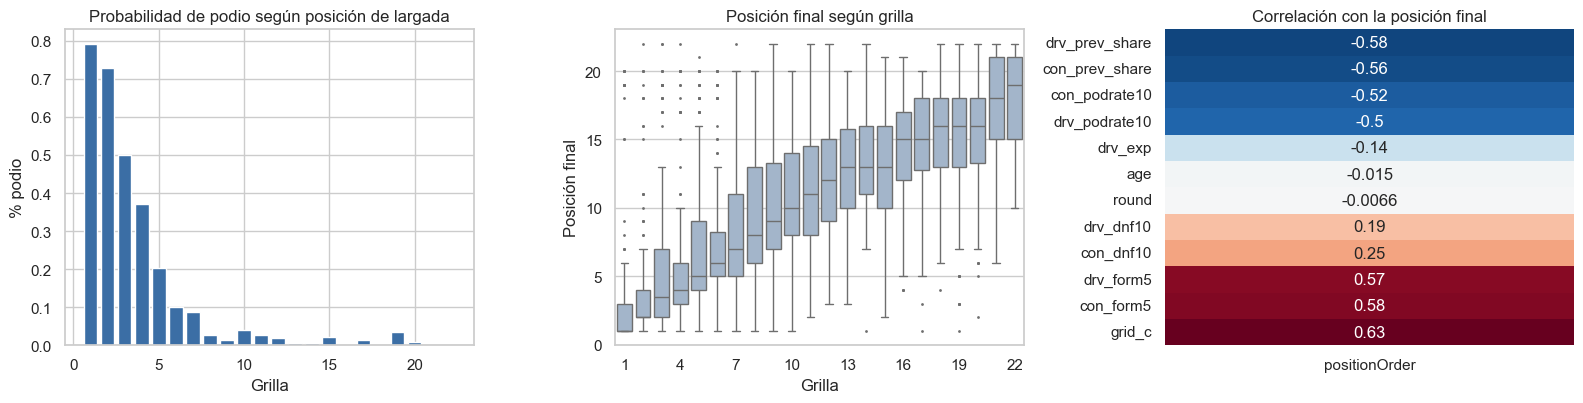

In [6]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
pod_grid = data.assign(g=data.grid_c.clip(upper=22)).groupby("g")["podium"].mean()
ax[0].bar(pod_grid.index, pod_grid.values, color="#3b6ea5")
ax[0].set(title="Probabilidad de podio según posición de largada", xlabel="Grilla", ylabel="% podio")
sns.boxplot(data=data[data.grid_c <= 22], x="grid_c", y="positionOrder", ax=ax[1], color="#9db4d0", fliersize=1)
ax[1].set(title="Posición final según grilla", xlabel="Grilla", ylabel="Posición final")
ax[1].set_xticks(range(0, 22, 3))
sns.heatmap(data[FEATURES + ["positionOrder"]].corr()[["positionOrder"]].drop("positionOrder").sort_values("positionOrder"),
            annot=True, cmap="RdBu_r", center=0, ax=ax[2], cbar=False)
ax[2].set_title("Correlación con la posición final")
plt.tight_layout(); plt.show()

**Lectura:** largar 1º da ~79 % de probabilidad de podio, 2º ~73 %, 3º ~50 %, y desde el 8º lugar en adelante es casi nulo. La grilla es la variable con mayor correlación con la posición final (0.63), seguida de la forma reciente de la escudería y del piloto (≈ 0.57). En 2020–2026 solo el 13 % de los autos no es clasificado: los autos modernos son muy confiables, por lo que el resultado depende sobre todo de dónde se larga.

### 2.5 Contexto: evolución del campeonato 2021

Replicamos el gráfico principal del notebook [F1 Race Traces 2021 (jtrotman, Kaggle)](https://www.kaggle.com/code/jtrotman/f1-race-traces-2026), del que proviene la configuración `DRIVER_C` / `DRIVER_LS` / `TEAM_C`: puntos acumulados ronda a ronda, con los compañeros de equipo en el mismo color y distinto estilo de línea. Los puntos incluyen las carreras sprint.

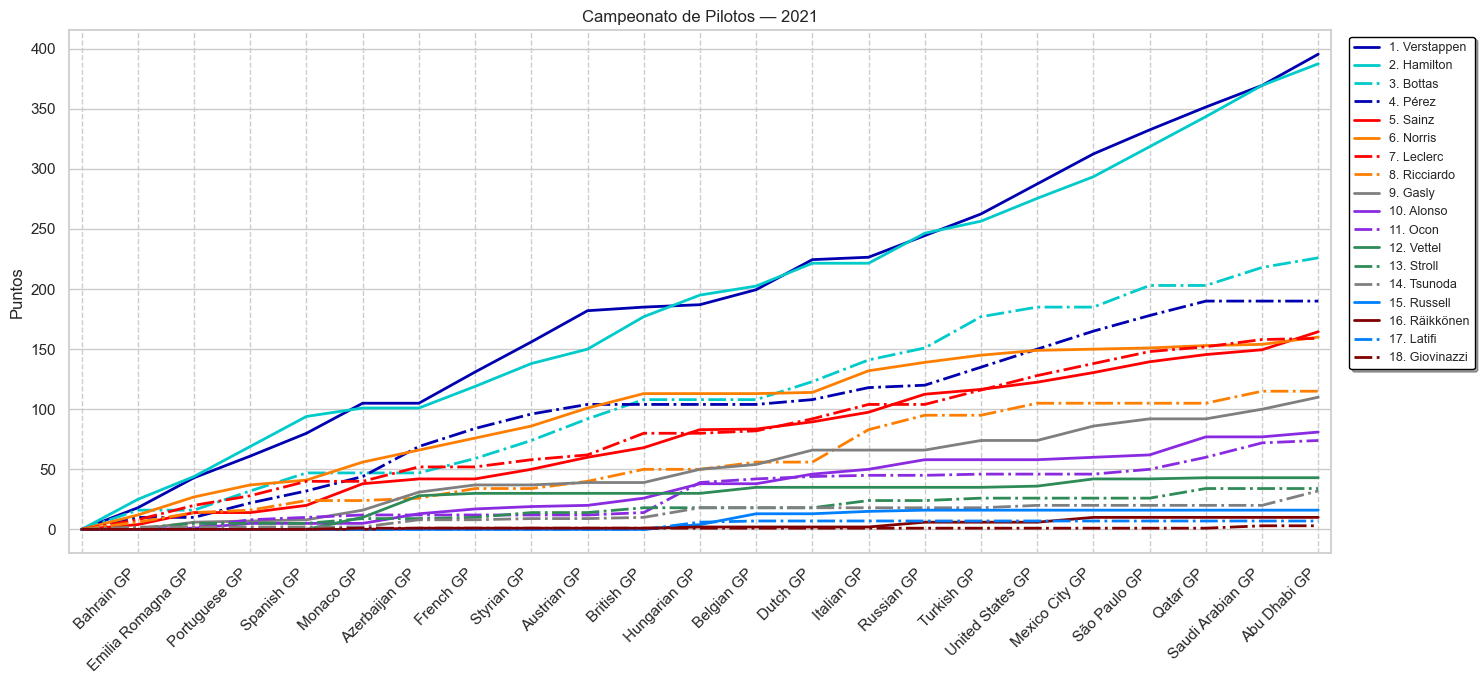

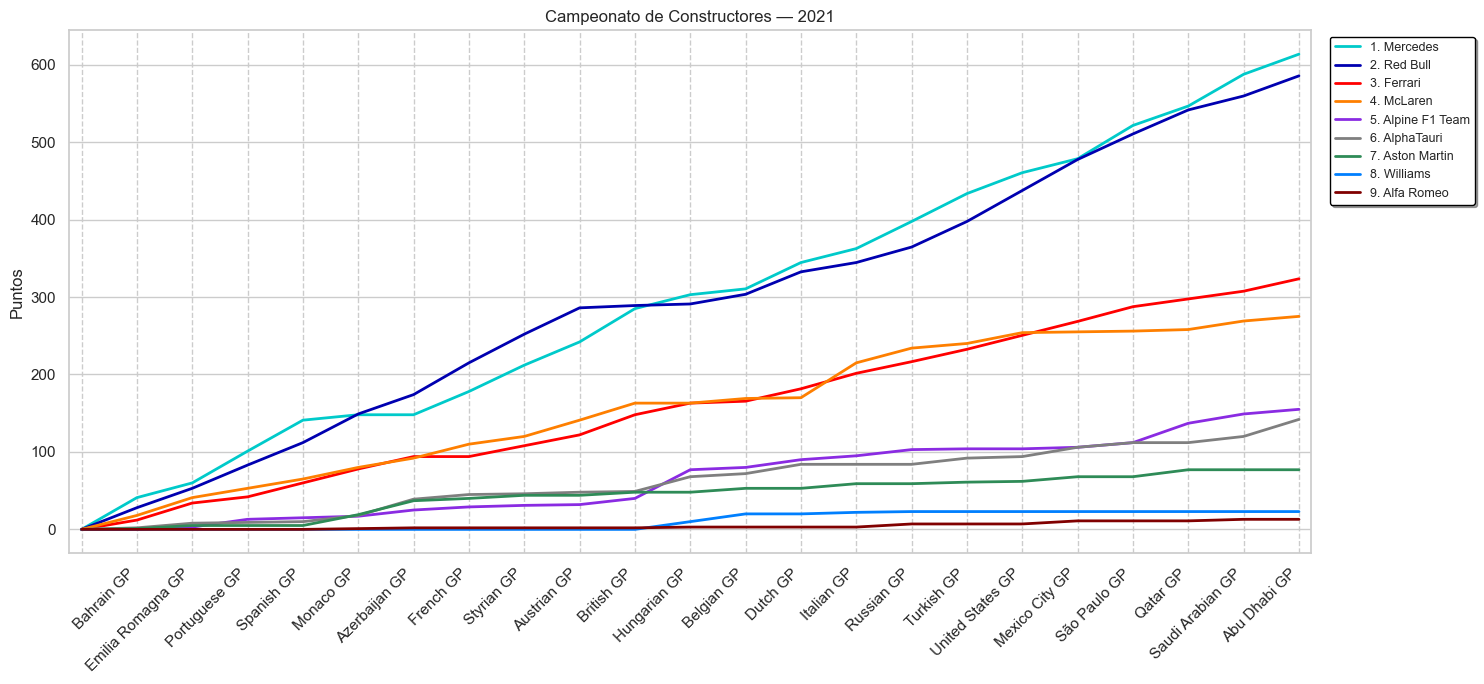

,piloto,points,wins
position,,,
1.000,Verstappen,395.500,10
2.000,Hamilton,387.500,8
3.000,Bottas,226.000,1
4.000,Pérez,190.000,1
5.000,Sainz,164.500,0


In [7]:
YEAR = 2021
plt.rc("axes", xmargin=0.01)

def traza_campeonato(st, key, color_fn, estilo_fn, titulo, nombres):
    st = st.merge(races[["raceId", "year", "round", "name"]], on="raceId").query("year == @YEAR")
    final = st[st["round"] == st["round"].max()].query("points > 0").sort_values("position")
    chart = st.pivot(index="round", columns=key, values="points")[final[key]]
    chart.loc[0] = 0  # origen antes de la primera carrera
    chart = chart.sort_index()
    etiquetas = [""] + races.query("year == @YEAR").sort_values("round")["name"].str.replace(" Grand Prix", " GP").tolist()

    fig, ax = plt.subplots(figsize=(15, 7))
    for _, fila in final.iterrows():
        k = fila[key]
        ax.plot(chart.index, chart[k], color=color_fn(k), ls=estilo_fn(k), lw=2,
                label=f"{int(fila['position'])}. {nombres[k]}")
    ax.set_xticks(chart.index, etiquetas[:len(chart)], rotation=45, ha="right")
    ax.grid(axis="x", linestyle="--")
    ax.set(title=f"{titulo} — {YEAR}", ylabel="Puntos")
    ax.legend(bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=9, shadow=True, edgecolor="black")
    plt.tight_layout(); plt.show()
    return final

apellido = drivers.set_index("driverId")["surname"]
equipo = constructors.set_index("constructorId")["name"]
fin_drv = traza_campeonato(dstand, "driverId", color_piloto, estilo_piloto, "Campeonato de Pilotos", apellido)
fin_con = traza_campeonato(cstand, "constructorId", color_equipo, lambda k: "-", "Campeonato de Constructores", equipo)
display(fin_drv.assign(piloto=fin_drv.driverId.map(apellido))[["position", "piloto", "points", "wins"]].head(5).set_index("position"))

**Lectura:** 2021 fue la temporada más pareja del período. Verstappen y Hamilton intercambiaron el liderato todo el año y llegaron a la última carrera empatados en puntos; Verstappen ganó el título en Abu Dabi. En constructores, Mercedes retuvo el campeonato frente a Red Bull. Esta paridad en la cima contrasta con el resto de la parrilla, que queda muy por detrás. Ese "muro" entre los equipos de punta y la mitad de la parrilla reaparece en el Insight 2 y en los grupos de DBSCAN.

## 3. Experimentos de clasificación — ¿podio sí/no?

- **Modelo principal:** Regresión Logística (con `StandardScaler`). Entrega probabilidades interpretables y coeficientes que se pueden explicar en la exposición.
- **Configuraciones evaluadas:** penalización `C` ∈ {0.01, 1, 100} y `class_weight` ∈ {None, balanced}. Las clases están desbalanceadas (~15 % podios).
- **Alternativa ejecutada:** Random Forest con `max_depth` ∈ {4, 8, None}.
- **Alternativa solo considerada (no ejecutada):** SVM con kernel RBF. No entrega probabilidades calibradas de forma nativa (requiere Platt scaling, lo que es costoso), su costo crece de forma cuadrática con el número de filas y sus decisiones no se pueden explicar con coeficientes. Como la frontera grilla→podio es casi monótona, no esperamos ganancia del truco del kernel.
- **Métricas:** ROC-AUC y PR-AUC (independientes del umbral), y precision / recall / F1 del podio. *Accuracy* no es informativa: predecir siempre "no podio" ya da 85 %.

In [8]:
def eval_clf(modelo, Xtr, ytr, Xev, yev, umbral=0.5):
    modelo.fit(Xtr, ytr)
    p = modelo.predict_proba(Xev)[:, 1]
    yhat = (p >= umbral).astype(int)
    return p, {"ROC-AUC": roc_auc_score(yev, p), "PR-AUC": average_precision_score(yev, p),
               "precision": precision_score(yev, yhat), "recall": recall_score(yev, yhat), "F1": f1_score(yev, yhat)}

configs_clf = {
    "LogReg C=0.01":            make_pipeline(StandardScaler(), LogisticRegression(C=0.01, max_iter=5000)),
    "LogReg C=1":               make_pipeline(StandardScaler(), LogisticRegression(C=1, max_iter=5000)),
    "LogReg C=100":             make_pipeline(StandardScaler(), LogisticRegression(C=100, max_iter=5000)),
    "LogReg C=1 balanced":      make_pipeline(StandardScaler(), LogisticRegression(C=1, class_weight="balanced", max_iter=5000)),
    "RandomForest depth=4":     RandomForestClassifier(n_estimators=300, max_depth=4, random_state=RANDOM_STATE, n_jobs=-1),
    "RandomForest depth=8":     RandomForestClassifier(n_estimators=300, max_depth=8, random_state=RANDOM_STATE, n_jobs=-1),
    "RandomForest sin límite (leaf=5)": RandomForestClassifier(n_estimators=300, min_samples_leaf=5, random_state=RANDOM_STATE, n_jobs=-1),
}
filas, probs_va = [], {}
for nombre, m in configs_clf.items():
    probs_va[nombre], met = eval_clf(m, tr[FEATURES], tr.podium, va[FEATURES], va.podium)
    filas.append({"configuración": nombre, **met})
tabla_clf = pd.DataFrame(filas).set_index("configuración")
tabla_clf.style.format("{:.3f}").highlight_max(axis=0, color="#cfe3c7")

,ROC-AUC,PR-AUC,precision,recall,F1
configuración,,,,,
LogReg C=0.01,0.916,0.601,0.565,0.542,0.553
LogReg C=1,0.930,0.670,0.615,0.667,0.640
LogReg C=100,0.931,0.670,0.623,0.667,0.644
LogReg C=1 balanced,0.929,0.662,0.453,0.931,0.609
RandomForest depth=4,0.928,0.656,0.679,0.528,0.594
RandomForest depth=8,0.928,0.654,0.651,0.569,0.607
RandomForest sin límite (leaf=5),0.932,0.674,0.641,0.569,0.603


**Comparación (validación 2024):**

- `C=1` y `C=100` quedan prácticamente empatados (ROC-AUC 0.930 vs 0.931, F1 0.640 vs 0.644). `C=0.01` **sobre-regulariza**: baja la ROC-AUC a 0.916 y el F1 a 0.553. `balanced` no mejora el ranking (0.929) y solo mueve el punto de operación: recall 0.93 con precision 0.45.
- El Random Forest **no supera** a la Logística. La mejor versión (sin límite de profundidad, `min_samples_leaf=5`) iguala la ROC-AUC (0.932) y la PR-AUC (0.674 vs 0.670), pero tiene **menor F1 (0.603 vs 0.640)**, y las versiones con profundidad limitada quedan por debajo. Ganar tres milésimas de AUC no justifica perder coeficientes interpretables. **Se ejecutó y se descarta.**
- **Decisión:** Regresión Logística, `C=1`, sin re-ponderar clases. La diferencia con `C=100` es ruido de muestreo, y `C=1` es la opción más estable. El desbalance se maneja **con el umbral**, no con los pesos, porque así se conserva el significado de la probabilidad.

### 3.1 Robustez de la elección: validación temporal en 3 años

Elegir con un solo año de validación (2024: 24 carreras, 72 podios) puede premiar diferencias que son ruido. Por eso repetimos la comparación con **validación temporal expansiva**: entrenar con 2020–2021 y validar en 2022, entrenar con 2020–2022 y validar en 2023, y entrenar con 2020–2023 y validar en 2024. Siempre se entrena con el pasado y se valida con el año siguiente, así que no hay fuga de información.

In [9]:
def cv_temporal(configs, target, metricas, años=(2022, 2023, 2024)):
    filas = []
    for año in años:
        a, b = data[data.year < año].copy(), data[data.year == año].copy()
        med = a[FEATURES].median()
        a[FEATURES], b[FEATURES] = a[FEATURES].fillna(med), b[FEATURES].fillna(med)
        for nombre, m in configs.items():
            m.fit(a[FEATURES], a[target])
            p = m.predict_proba(b[FEATURES])[:, 1] if hasattr(m, "predict_proba") else m.predict(b[FEATURES])
            filas.append({"configuración": nombre, "año": año, **{k: f(b[target], p) for k, f in metricas.items()}})
    t = pd.DataFrame(filas).groupby("configuración")[list(metricas)].agg(["mean", "std"])
    t.columns = [f"{m} {e}" for m, e in t.columns]
    return t

cv_clf = cv_temporal(configs_clf, "podium", {"ROC-AUC": roc_auc_score, "PR-AUC": average_precision_score,
                                             "F1@0.5": lambda y, p: f1_score(y, p >= 0.5)})
cv_clf.sort_values("PR-AUC mean", ascending=False).style.format("{:.3f}")

,ROC-AUC mean,ROC-AUC std,PR-AUC mean,PR-AUC std,F1@0.5 mean,F1@0.5 std
configuración,,,,,,
LogReg C=100,0.932,0.005,0.699,0.051,0.622,0.041
LogReg C=1,0.932,0.006,0.694,0.053,0.616,0.048
LogReg C=1 balanced,0.931,0.005,0.691,0.053,0.619,0.054
RandomForest sin límite (leaf=5),0.928,0.004,0.671,0.072,0.609,0.025
RandomForest depth=4,0.927,0.003,0.670,0.073,0.616,0.019
LogReg C=0.01,0.916,0.012,0.644,0.051,0.532,0.036
RandomForest depth=8,0.922,0.006,0.631,0.073,0.598,0.024


**Lectura:** la elección se sostiene. En promedio de 3 años, la Logística con `C=1` o `C=100` tiene la mejor ROC-AUC (0.932 ± 0.006) y una **PR-AUC mayor que la de todos los Random Forest** (0.69–0.70 vs 0.63–0.67). `C=0.01` vuelve a ser el peor. Las diferencias entre `C=1`, `C=100` y `balanced` (≤ 0.006 en F1) son menores que su propia variación entre años (± 0.04–0.05), así que no hay una ganadora entre esas tres y mantenemos `C=1` por simplicidad.

### 3.2 Comparación de dos umbrales

,umbral,precision,recall,F1,podios predichos
0.50 (por defecto),0.500,0.615,0.667,0.640,78
óptimo F1 en validación,0.300,0.546,0.903,0.681,119


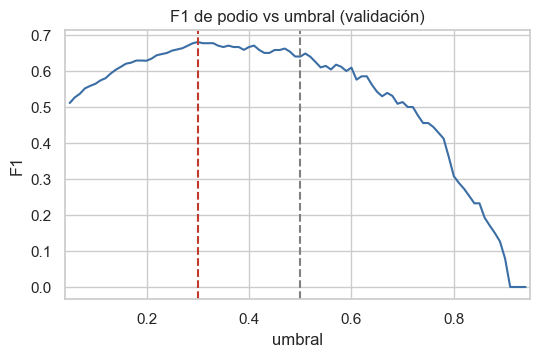

Umbral elegido: 0.30


In [10]:
p_lr = probs_va["LogReg C=1"]
umbrales = np.arange(0.05, 0.95, 0.01)
f1s = [f1_score(va.podium, p_lr >= u) for u in umbrales]
u_opt = float(umbrales[int(np.argmax(f1s))])

fila = lambda u: {"umbral": round(u, 2), "precision": precision_score(va.podium, p_lr >= u),
                  "recall": recall_score(va.podium, p_lr >= u), "F1": f1_score(va.podium, p_lr >= u),
                  "podios predichos": int((p_lr >= u).sum())}
display(pd.DataFrame([fila(0.5), fila(u_opt)], index=["0.50 (por defecto)", "óptimo F1 en validación"]))

plt.figure(figsize=(6, 3.5))
plt.plot(umbrales, f1s, color="#3b6ea5"); plt.axvline(0.5, ls="--", c="grey"); plt.axvline(u_opt, ls="--", c="#c0392b")
plt.title("F1 de podio vs umbral (validación)"); plt.xlabel("umbral"); plt.ylabel("F1"); plt.show()
print(f"Umbral elegido: {u_opt:.2f}")

Con el umbral 0.5 el modelo marca 78 podios en 2024, con precision 0.62 y recall 0.67. El umbral óptimo en validación es **0.30**: marca 119 podios, captura el 90 % de los podios reales (recall 0.90) y sube el F1 a 0.68, a costa de bajar la precision a 0.55. El umbral se elige **en validación, nunca en prueba**, y la elección depende del uso:

- Para una **apuesta** conviene más precision (umbral 0.5).
- Para que un **equipo** detecte oportunidades de podio conviene más recall (umbral 0.30).

### 3.3 Evaluación final en prueba (2025–2026)

,ROC-AUC,PR-AUC,precision,recall,F1
umbral 0.50,0.938,0.730,0.686,0.675,0.680
umbral 0.30,0.938,0.730,0.551,0.837,0.665


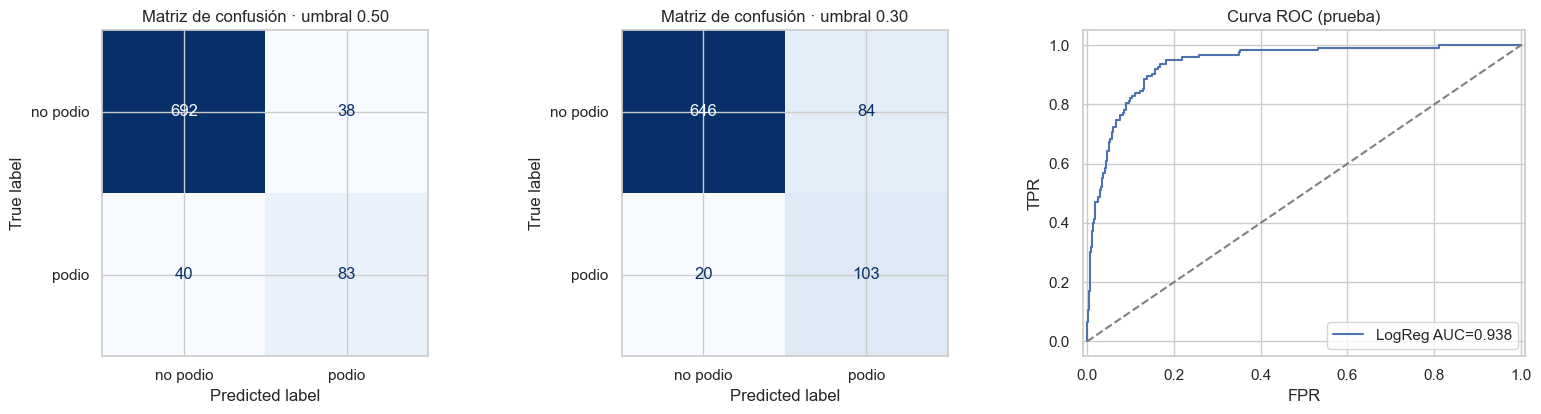

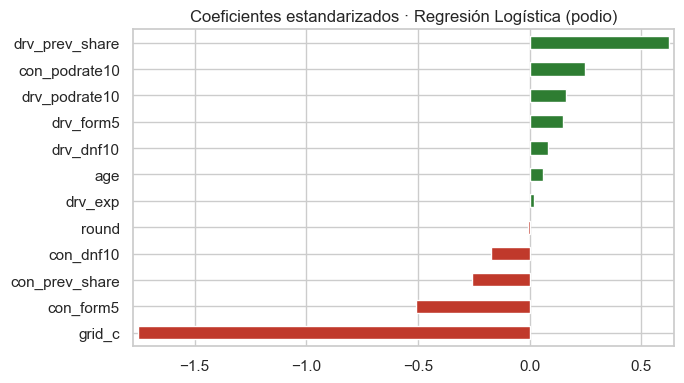

Brier score: modelo 0.065 | predecir siempre la tasa base 0.123


,n,prob_predicha,tasa_real_de_podio
"(-0.001, 0.1]",595,0.014,0.010
"(0.1, 0.3]",71,0.190,0.197
"(0.3, 0.5]",66,0.387,0.303
"(0.5, 0.7]",59,0.587,0.542
"(0.7, 0.9]",61,0.801,0.820
"(0.9, 1.0]",1,0.912,1.000


In [11]:
clf_final = make_pipeline(StandardScaler(), LogisticRegression(C=1, max_iter=5000))
p_te, met_05 = eval_clf(clf_final, trva[FEATURES], trva.podium, te[FEATURES], te.podium, 0.5)
met_opt = {k: v for k, v in zip(["precision", "recall", "F1"],
           [precision_score(te.podium, p_te >= u_opt), recall_score(te.podium, p_te >= u_opt), f1_score(te.podium, p_te >= u_opt)])}
display(pd.DataFrame([met_05, {**met_05, **met_opt}], index=["umbral 0.50", f"umbral {u_opt:.2f}"]))

fig, ax = plt.subplots(1, 3, figsize=(16, 4.3))
for a, u in zip(ax[:2], [0.5, u_opt]):
    ConfusionMatrixDisplay(confusion_matrix(te.podium, p_te >= u), display_labels=["no podio", "podio"]).plot(ax=a, cmap="Blues", colorbar=False)
    a.set_title(f"Matriz de confusión · umbral {u:.2f}")
fpr, tpr, _ = roc_curve(te.podium, p_te)
ax[2].plot(fpr, tpr, label=f"LogReg AUC={met_05['ROC-AUC']:.3f}")
ax[2].plot([0, 1], [0, 1], "--", c="grey"); ax[2].set(title="Curva ROC (prueba)", xlabel="FPR", ylabel="TPR"); ax[2].legend()
plt.tight_layout(); plt.show()

coefs = pd.Series(clf_final[-1].coef_[0], index=FEATURES).sort_values()
plt.figure(figsize=(7, 4)); coefs.plot.barh(color=np.where(coefs > 0, "#2e7d32", "#c0392b"))
plt.title("Coeficientes estandarizados · Regresión Logística (podio)"); plt.tight_layout(); plt.show()

# ¿las probabilidades significan lo que dicen? (calibración en prueba)
from sklearn.metrics import brier_score_loss
print(f"Brier score: modelo {brier_score_loss(te.podium, p_te):.3f} | "
      f"predecir siempre la tasa base {brier_score_loss(te.podium, np.full(len(te), trva.podium.mean())):.3f}")
tramos = pd.cut(p_te, [0, .1, .3, .5, .7, .9, 1], include_lowest=True)
pd.DataFrame({"p": p_te, "y": te.podium.values}).groupby(tramos, observed=True).agg(
    n=("y", "size"), prob_predicha=("p", "mean"), tasa_real_de_podio=("y", "mean"))

**Resultado en prueba (2025–2026):**

- **ROC-AUC 0.938 y PR-AUC 0.730**, en línea con la validación (0.930 / 0.670). El modelo **no se degradó** al pasar a datos nuevos, y eso que 2026 trae reglamento técnico nuevo.
- **Umbral 0.50:** precision 0.69, recall 0.68 y F1 0.68 (la matriz muestra cuántos podios acierta y cuántos falsos positivos marca).
- **Umbral 0.30** (elegido en 2024): recall 0.84 y precision 0.55. Detecta más podios, pero **en prueba su F1 (0.665) quedó levemente por debajo del de 0.50 (0.680)**: la ventaja en F1 que tenía en validación no se trasladó. El umbral bajo sigue sirviendo cuando importa no perder podios (recall), pero no es mejor en general.
- **Coeficientes (estandarizados):** `grid_c` domina (−1.75: largar más atrás baja mucho la probabilidad de podio). Le siguen la proporción de puntos del piloto en el campeonato (+0.62) y la forma reciente de la escudería (`con_form5` −0.51: una peor posición media reciente del equipo implica menos podio). El resto pesa menos de 0.3. `con_prev_share` sale con signo negativo (−0.26), un efecto de la colinealidad con `drv_prev_share` que no debe leerse por separado.
- **Calibración:** el Brier score del modelo es la mitad del de predecir siempre la tasa base, y en cada tramo la probabilidad predicha se parece a la tasa real de podios. Entre 0.3 y 0.5 el modelo sobreestima un poco (predice 0.39 y la tasa real es 0.30). Por eso tiene sentido usar la probabilidad para comparar umbrales.

## 4. Experimentos de regresión — posición final

- **Línea base:** predecir posición final = posición de largada.
- **Modelo principal:** regresión lineal con penalización. Se evalúan OLS sin penalizar, **Ridge** con α ∈ {1, 10, 100} y **Lasso** con α ∈ {0.01, 0.1, 0.5}. Corresponde regularizar porque varias variables están correlacionadas entre sí (forma, % de podios y puntos del campeonato miden el mismo "nivel").
- **Alternativa ejecutada:** Random Forest Regressor (`min_samples_leaf` ∈ {5, 20}).
- **Métricas:** MAE (error medio en puestos, fácil de comunicar), RMSE (castiga los errores grandes, típicamente abandonos) y R².

In [12]:
def eval_reg(modelo, Xtr, ytr, Xev, yev):
    modelo.fit(Xtr, ytr)
    p = modelo.predict(Xev)
    return p, {"MAE": mean_absolute_error(yev, p), "RMSE": root_mean_squared_error(yev, p), "R2": r2_score(yev, p)}

configs_reg = {
    "OLS (sin penalización)": make_pipeline(StandardScaler(), LinearRegression()),
    "Ridge α=1":    make_pipeline(StandardScaler(), Ridge(alpha=1)),
    "Ridge α=10":   make_pipeline(StandardScaler(), Ridge(alpha=10)),
    "Ridge α=100":  make_pipeline(StandardScaler(), Ridge(alpha=100)),
    "Lasso α=0.01": make_pipeline(StandardScaler(), Lasso(alpha=0.01, max_iter=20000)),
    "Lasso α=0.1":  make_pipeline(StandardScaler(), Lasso(alpha=0.1, max_iter=20000)),
    "Lasso α=0.5":  make_pipeline(StandardScaler(), Lasso(alpha=0.5, max_iter=20000)),
    "RandomForest leaf=5":  RandomForestRegressor(n_estimators=300, min_samples_leaf=5, random_state=RANDOM_STATE, n_jobs=-1),
    "RandomForest leaf=20": RandomForestRegressor(n_estimators=300, min_samples_leaf=20, random_state=RANDOM_STATE, n_jobs=-1),
}
base = va.grid_c.clip(upper=va.positionOrder.max())
filas = [{"configuración": "Línea base: posición = grilla", "MAE": mean_absolute_error(va.positionOrder, base),
          "RMSE": root_mean_squared_error(va.positionOrder, base), "R2": r2_score(va.positionOrder, base)}]
modelos_reg = {}
for nombre, m in configs_reg.items():
    _, met = eval_reg(m, tr[FEATURES], tr.positionOrder, va[FEATURES], va.positionOrder)
    modelos_reg[nombre] = m
    filas.append({"configuración": nombre, **met})
tabla_reg = pd.DataFrame(filas).set_index("configuración")
tabla_reg.style.format("{:.3f}").highlight_min(subset=["MAE", "RMSE"], color="#cfe3c7").highlight_max(subset=["R2"], color="#cfe3c7")

,MAE,RMSE,R2
configuración,,,
Línea base: posición = grilla,2.894,4.217,0.463
OLS (sin penalización),2.863,3.835,0.556
Ridge α=1,2.862,3.835,0.556
Ridge α=10,2.861,3.835,0.556
Ridge α=100,2.877,3.850,0.553
Lasso α=0.01,2.862,3.837,0.556
Lasso α=0.1,2.883,3.835,0.556
Lasso α=0.5,3.054,3.892,0.543
RandomForest leaf=5,3.318,4.174,0.474


In [13]:
# ¿qué variables apaga Lasso a medida que sube α?
coef_tab = pd.DataFrame({n: modelos_reg[n][-1].coef_ for n in ["OLS (sin penalización)", "Ridge α=100", "Lasso α=0.1", "Lasso α=0.5"]},
                        index=FEATURES)
coef_tab.style.format("{:.2f}").background_gradient(cmap="RdBu_r", axis=None, vmin=-3, vmax=3)

,OLS (sin penalización),Ridge α=100,Lasso α=0.1,Lasso α=0.5
grid_c,1.93,1.80,1.90,1.71
drv_exp,-0.32,-0.33,-0.24,-0.00
drv_form5,0.00,0.35,0.00,0.00
drv_podrate10,0.18,0.00,-0.00,-0.00
drv_dnf10,-0.19,-0.22,-0.07,-0.00
con_form5,1.25,0.84,1.09,1.01
con_podrate10,-0.17,-0.10,-0.00,-0.00
con_dnf10,-0.08,-0.03,-0.00,0.00
drv_prev_share,-1.31,-0.74,-0.96,-0.82
con_prev_share,0.40,-0.18,-0.00,-0.00


- **Todos los modelos lineales superan a la línea base** (R² 0.553–0.556 vs 0.463; RMSE 3.84 vs 4.22). El contexto (auto, forma, campeonato) agrega información real, sobre todo para evitar errores grandes.
- OLS, Ridge y Lasso con α bajo quedan **empatados en error** (MAE ≈ 2.86, R² 0.556). La diferencia aparece en los **coeficientes**: en OLS, `con_prev_share` sale **positivo (+0.40)**, como si ir mejor en el campeonato de constructores empeorara la posición, y `drv_form5` queda en 0. Es un síntoma de colinealidad entre las variables de forma y de campeonato. Ridge α=100 corrige los signos (`con_prev_share` −0.18, `drv_form5` +0.35) casi sin costo (MAE 2.877 vs 2.861).
- Lasso α=0.5 deja **solo 3 variables** (`grid_c`, `con_form5` y `drv_prev_share`) y apaga las otras 9. Es útil como diagnóstico de redundancia, pero el MAE sube a 3.05.
- El Random Forest **empeora** (MAE 3.05–3.32, R² 0.47–0.53). Con ~1.700 filas de entrenamiento y una relación casi lineal entre grilla y posición, el bosque sobreajusta. **Se ejecutó y se descarta.**
- **Decisión:** **Ridge α=100**. Tiene el mismo error que OLS, pero sus coeficientes son estables y tienen el signo esperado, lo que permite interpretarlos en la exposición.

In [14]:
cv_reg = cv_temporal(configs_reg, "positionOrder", {"MAE": mean_absolute_error, "RMSE": root_mean_squared_error, "R2": r2_score})
cv_reg.sort_values("MAE mean").style.format("{:.3f}")

,MAE mean,MAE std,RMSE mean,RMSE std,R2 mean,R2 std
configuración,,,,,,
Ridge α=100,3.210,0.311,4.278,0.421,0.445,0.107
Lasso α=0.1,3.212,0.301,4.263,0.416,0.449,0.106
Lasso α=0.01,3.217,0.341,4.307,0.480,0.437,0.124
Ridge α=10,3.217,0.343,4.309,0.482,0.436,0.125
Ridge α=1,3.223,0.350,4.318,0.495,0.434,0.128
OLS (sin penalización),3.224,0.350,4.319,0.496,0.433,0.129
RandomForest leaf=20,3.357,0.289,4.329,0.370,0.433,0.095
Lasso α=0.5,3.395,0.301,4.300,0.381,0.440,0.097
RandomForest leaf=5,3.499,0.193,4.448,0.292,0.403,0.078


**Validación temporal (3 años):** **Ridge α=100 obtiene el menor MAE promedio (3.21) y el mayor R² (0.445)**, y además la **menor variación entre años** de todos los modelos lineales (± 0.31 en MAE y ± 0.11 en R², frente a ± 0.35 y ± 0.13 de OLS). Esto confirma que la penalización estabiliza el modelo cuando cambia la temporada. Los Random Forest siguen por detrás (MAE 3.36–3.50).

**Alternativa solo considerada (no ejecutada): SVR con kernel RBF.** No la ejecutamos porque la relación entre la grilla y la posición es casi lineal (correlación 0.63), así que el truco del kernel no tiene una no-linealidad que capturar. Además, perderíamos la interpretación por coeficientes, que es lo que permite discutir el peso del auto frente al piloto.

,MAE,RMSE,R2
Línea base (grilla),3.411,5.043,0.303
Ridge α=100,3.410,4.507,0.444


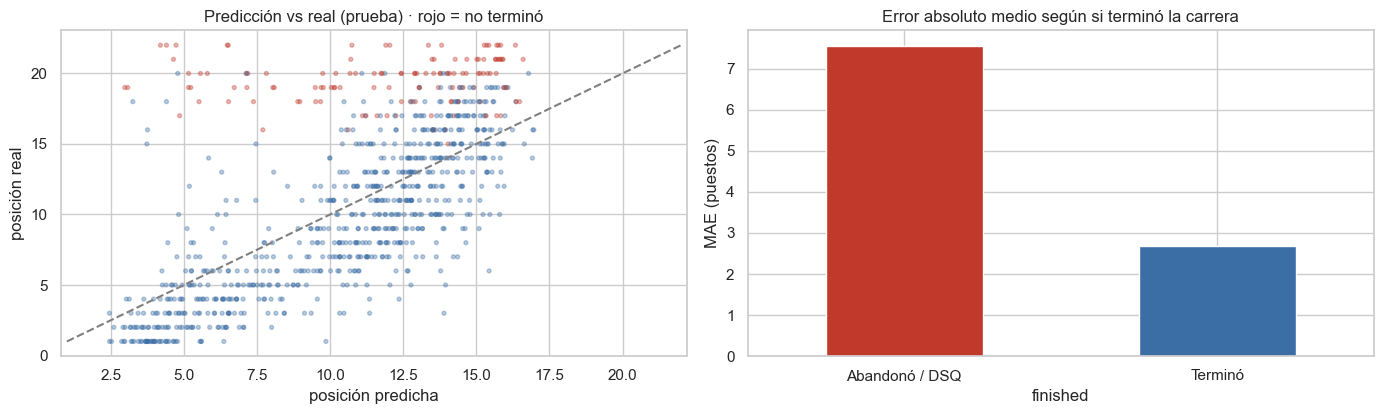

In [15]:
reg_final = make_pipeline(StandardScaler(), Ridge(alpha=100))
pred_te, met_te = eval_reg(reg_final, trva[FEATURES], trva.positionOrder, te[FEATURES], te.positionOrder)
base_te = te.grid_c.clip(upper=te.positionOrder.max())
display(pd.DataFrame([{"MAE": mean_absolute_error(te.positionOrder, base_te), "RMSE": root_mean_squared_error(te.positionOrder, base_te),
                       "R2": r2_score(te.positionOrder, base_te)}, met_te], index=["Línea base (grilla)", "Ridge α=100"]))

te["pred_pos"] = pred_te
te["error_abs"] = (te.positionOrder - te.pred_pos).abs()
fig, ax = plt.subplots(1, 2, figsize=(14, 4.3))
ax[0].scatter(te.pred_pos, te.positionOrder, s=8, alpha=.35, c=te.finished.map({1: "#3b6ea5", 0: "#c0392b"}))
ax[0].plot([1, 22], [1, 22], "--", c="grey")
ax[0].set(title="Predicción vs real (prueba) · rojo = no terminó", xlabel="posición predicha", ylabel="posición real")
te.groupby(te.finished.map({1: "Terminó", 0: "Abandonó / DSQ"}))["error_abs"].mean().plot.bar(ax=ax[1], color=["#c0392b", "#3b6ea5"], rot=0)
ax[1].set(title="Error absoluto medio según si terminó la carrera", ylabel="MAE (puestos)")
plt.tight_layout(); plt.show()

**Resultado en prueba (2025–2026):** Ridge α=100 obtiene **MAE 3.41, RMSE 4.51 y R² 0.444**, frente a MAE 3.41, RMSE 5.04 y R² 0.303 de la línea base "posición = grilla".

- **El MAE es igual al de la línea base, pero el RMSE baja un 11 % y el R² sube 0.14.** El modelo no acierta más en el caso típico, pero comete **muchos menos errores grandes**. La celda siguiente muestra de dónde viene esa mejora.
- El error se concentra en los **abandonos**: cuando el piloto no termina, el error medio es ~7,5 puestos, y cuando termina es ~2,7. Los abandonos son imprevisibles con información previa a la carrera, y eso pone un techo al R² alcanzable.

In [16]:
# ¿dónde gana la Ridge a la grilla? autos de punta (≥50% de podios recientes del equipo) que largan 8º o más atrás
te["base_grid"] = te.grid_c.clip(upper=te.positionOrder.max())
remontada = (te.grid_c >= 8) & (te.con_podrate10 >= 0.5)
pd.DataFrame({g: {"filas": len(d), "posición real media": d.positionOrder.mean(),
                  "MAE grilla": mean_absolute_error(d.positionOrder, d.base_grid),
                  "MAE Ridge": mean_absolute_error(d.positionOrder, d.pred_pos)}
              for g, d in [("auto de punta largando atrás", te[remontada]), ("resto", te[~remontada])]}).T

,filas,posición real media,MAE grilla,MAE Ridge
auto de punta largando atrás,51.000,10.824,5.294,3.869
resto,802.000,10.934,3.292,3.381


**Evidencia:** en las 51 largadas de un **auto de punta desde el 8º lugar o más atrás**, la grilla se equivoca 5.3 puestos en promedio y la Ridge 3.9: el modelo anticipa la remontada. En el resto de los casos, la Ridge es **levemente peor** que la grilla (3.38 vs 3.29). La ganancia del modelo está concentrada en esas situaciones atípicas, que son justamente las que más interesan a un analista.

## 5. DBSCAN — perfiles de piloto (2020–2026)

**Unidad de análisis:** un piloto con al menos 30 largadas en 2020–2026 (31 pilotos), para que las tasas sean estables. Resumimos su carrera deportiva en 6 rasgos y los estandarizamos, porque DBSCAN usa distancias:

`podium_rate`, `win_rate`, `dnf_rate`, `avg_grid`, `avg_gain` (puestos ganados = grilla − final, solo cuando terminó) y `pts_share` (proporción media de puntos frente al líder).

DBSCAN **no recibe un número de grupos**: lo define la densidad (`eps`, `min_samples`). Los puntos que no caen en ninguna zona densa quedan como **ruido** (etiqueta −1), que es justamente lo que interesa para la pregunta de anomalías.

In [17]:
mod = df[df.year.between(2020, 2026)].copy()
mod["win"] = (mod.positionOrder == 1).astype(int)
mod["gain"] = np.where(mod.finished == 1, mod.grid_c - mod.positionOrder, np.nan)
mod = mod.merge(share_previo(dstand, "driverId").rename(columns={"share": "share_now"}), on=["driverId", "year", "round"], how="left")

perf = (mod.groupby(["driverId", "nombre"])
          .agg(starts=("raceId", "count"), podium_rate=("podium", "mean"), win_rate=("win", "mean"),
               dnf_rate=("finished", lambda s: 1 - s.mean()), avg_grid=("grid_c", "mean"),
               avg_gain=("gain", "mean"), pts_share=("share_now", "mean"))
          .reset_index())
perf = perf[perf.starts >= 30].reset_index(drop=True)
RASGOS = ["podium_rate", "win_rate", "dnf_rate", "avg_grid", "avg_gain", "pts_share"]
Xp = StandardScaler().fit_transform(perf[RASGOS].fillna(perf[RASGOS].median()))
print(f"{len(perf)} pilotos con ≥30 largadas en 2020–2026")
perf[RASGOS].describe().T[["mean", "std", "min", "max"]]

31 pilotos con ≥30 largadas en 2020–2026


,mean,std,min,max
podium_rate,0.117,0.174,0.000,0.709
win_rate,0.039,0.088,0.000,0.439
dnf_rate,0.130,0.037,0.061,0.208
avg_grid,11.557,3.807,3.568,17.426
avg_gain,1.136,0.823,-0.089,3.147
pts_share,0.205,0.227,0.000,0.830


### 5.1 Elegir el rango de `eps`: gráfico de k-distancias

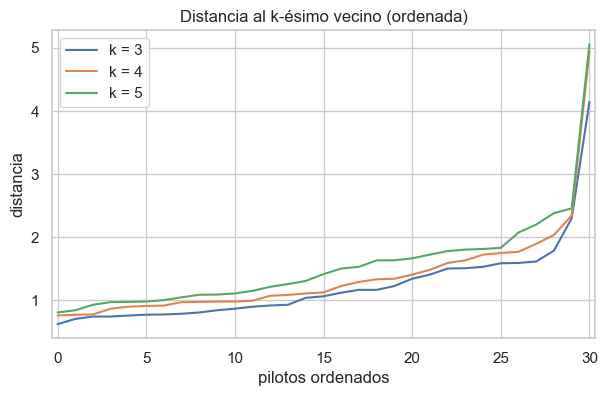

In [18]:
fig, ax = plt.subplots(figsize=(7, 4))
for k in [3, 4, 5]:
    d, _ = NearestNeighbors(n_neighbors=k).fit(Xp).kneighbors(Xp)
    ax.plot(np.sort(d[:, -1]), label=f"k = {k}")
ax.set(title="Distancia al k-ésimo vecino (ordenada)", xlabel="pilotos ordenados", ylabel="distancia"); ax.legend()
plt.show()

El "codo" de la curva (donde la distancia empieza a crecer rápido) está alrededor de 1.4–1.8 para k = 4, y sobre 2.3 solo quedan los 2–3 pilotos más extremos. Probamos `eps` de 0.8 a 1.6, combinado con `min_samples` ∈ {3, 4, 5}: **15 combinaciones**.

In [19]:
grid_db = []
for eps in [0.8, 1.0, 1.2, 1.4, 1.6]:
    for ms in [3, 4, 5]:
        lab = DBSCAN(eps=eps, min_samples=ms).fit_predict(Xp)
        n_cl = len(set(lab)) - (1 if -1 in lab else 0)
        tam = sorted(pd.Series(lab[lab >= 0]).value_counts().tolist(), reverse=True)
        sil = silhouette_score(Xp[lab >= 0], lab[lab >= 0]) if n_cl >= 2 else np.nan  # solo puntos agrupados
        grid_db.append({"eps": eps, "min_samples": ms, "nº clústeres (sin ruido)": n_cl,
                        "ruido (n)": int((lab == -1).sum()), "% ruido": (lab == -1).mean(), "silueta": sil, "tamaños": tam})
tabla_db = pd.DataFrame(grid_db)
tabla_db.style.format({"% ruido": "{:.1%}", "eps": "{:.1f}", "silueta": "{:.3f}"}, na_rep="—")

,eps,min_samples,nº clústeres (sin ruido),ruido (n),% ruido,silueta,tamaños
0,0.8,3,2,20,64.5%,0.376,"[6, 5]"
1,0.8,4,1,26,83.9%,—,[5]
2,0.8,5,0,31,100.0%,—,[]
3,1.0,3,1,16,51.6%,—,[15]
4,1.0,4,1,16,51.6%,—,[15]
5,1.0,5,1,18,58.1%,—,[13]
6,1.2,3,2,9,29.0%,0.417,"[19, 3]"
7,1.2,4,1,12,38.7%,—,[19]
8,1.2,5,1,12,38.7%,—,[19]
9,1.4,3,2,7,22.6%,0.491,"[19, 5]"


**Criterio de selección:** buscamos una configuración que:

1. separe más de un grupo con sentido deportivo (no un único bloque),
2. deje un nivel de ruido moderado (≈ 10–25 %), para que "ruido" signifique *atípico* y no *todo lo que no es el bloque central*,
3. sea estable: que las combinaciones vecinas den resultados parecidos.

- `eps=0.8–1.0`: entre 52 % y 100 % de ruido. Es demasiado estricto para solo 31 pilotos en 6 dimensiones.
- `eps=1.2`: 29–39 % de ruido y, con `min_samples` 4 o 5, **un solo** grupo. Todavía marca como atípicos a muchos pilotos comunes.
- `eps=1.6`: el bloque central absorbe a 22–28 pilotos y queda un solo grupo (salvo con `min_samples=5`). Se pierde la estructura.
- **`eps=1.4`**: **2 grupos (19 + 5 pilotos) con 22,6 % de ruido**, y el resultado es **idéntico con `min_samples` 3 y 4**. Es la zona estable, y la silueta de los puntos agrupados (0.49) es mejor que la de `eps=1.2, min_samples=3` (0.42). `eps=1.6, min_samples=5` tiene una silueta parecida (0.50), pero su grupo principal absorbe a casi toda la parrilla (22 pilotos).

**Configuración final: `eps=1.4`, `min_samples=4`** (2 clústeres, 7 pilotos de ruido = 22,6 %). Preferimos 4 sobre 3 porque exige una densidad más estricta con el mismo resultado. Con 5 el grupo de 5 pilotos ya no alcanza la densidad mínima y desaparece.

In [20]:
EPS, MS = 1.4, 4
perf["cluster"] = DBSCAN(eps=EPS, min_samples=MS).fit_predict(Xp)
resumen = (perf.groupby("cluster")[RASGOS + ["starts"]].mean()
             .assign(n_pilotos=perf.groupby("cluster").size()))
display(resumen.style.format("{:.3f}", subset=RASGOS).format("{:.0f}", subset=["starts", "n_pilotos"]))

for c in sorted(perf.cluster.unique()):
    nombres = perf[perf.cluster == c].sort_values("pts_share", ascending=False).nombre.head(12).tolist()
    print(f"cluster {c:>2} ({(perf.cluster == c).sum()} pilotos): {', '.join(nombres)}")

,podium_rate,win_rate,dnf_rate,avg_grid,avg_gain,pts_share,starts,n_pilotos
cluster,,,,,,,,
-1,0.257,0.119,0.126,9.852,1.657,0.381,109,7
0,0.024,0.003,0.138,13.476,1.172,0.075,77,19
1,0.273,0.064,0.105,6.655,0.268,0.452,136,5


cluster -1 (7 pilotos): Max Verstappen, Lewis Hamilton, Andrea Kimi Antonelli, Sergio Pérez, Lance Stroll, Alexander Albon, Kimi Räikkönen
cluster  0 (19 pilotos): Valtteri Bottas, Fernando Alonso, Daniel Ricciardo, Isack Hadjar, Pierre Gasly, Esteban Ocon, Sebastian Vettel, Oliver Bearman, Liam Lawson, Nico Hülkenberg, Yuki Tsunoda, Kevin Magnussen
cluster  1 (5 pilotos): Charles Leclerc, Lando Norris, Oscar Piastri, George Russell, Carlos Sainz


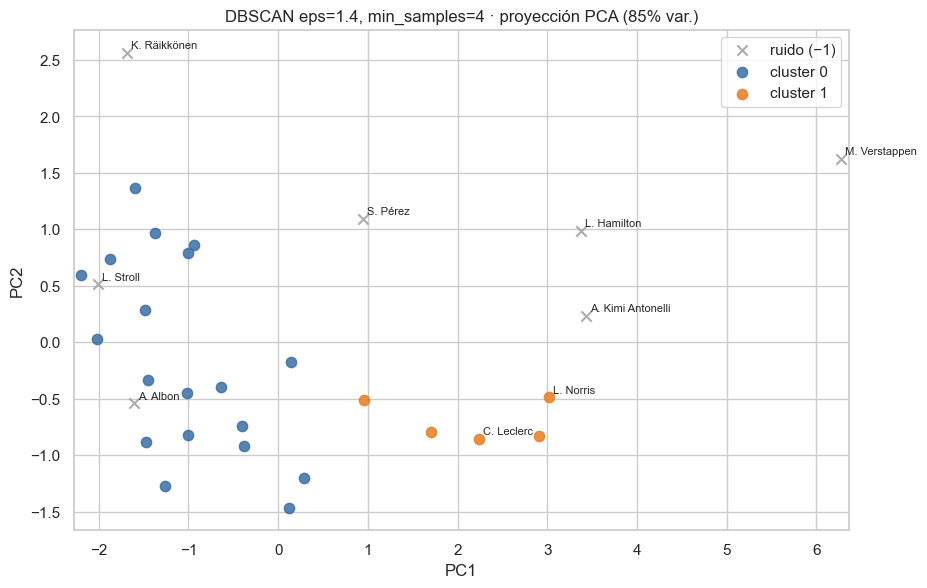

In [21]:
pca = PCA(n_components=2, random_state=RANDOM_STATE)
Z = pca.fit_transform(Xp)
fig, ax = plt.subplots(figsize=(10, 6.5))
pal = dict(zip(sorted(perf.cluster.unique()), ["#9e9e9e", "#3b6ea5", "#e67e22", "#2e7d32", "#8e44ad", "#c0392b"]))
for c, sub in perf.groupby("cluster"):
    idx = sub.index
    ax.scatter(Z[idx, 0], Z[idx, 1], s=55, c=pal[c], label="ruido (−1)" if c == -1 else f"cluster {c}",
               marker="x" if c == -1 else "o", alpha=.85)
for i, r in perf.iterrows():
    if r.cluster == -1 or r.pts_share > 0.5:
        ax.annotate(r.nombre[0] + ". " + r.nombre.split(" ", 1)[-1], Z[i], fontsize=8, xytext=(3, 3), textcoords="offset points")
ax.set(title=f"DBSCAN eps={EPS}, min_samples={MS} · proyección PCA ({pca.explained_variance_ratio_.sum():.0%} var.)",
       xlabel="PC1", ylabel="PC2"); ax.legend()
plt.show()

**Caracterización (ver la tabla de medias y la lista de nombres):**

- **Cluster 0 — "mitad y fondo de parrilla" (19 pilotos):** largan en promedio ~13º, 2,4 % de podios, prácticamente sin victorias (0,3 %) y 7,5 % de los puntos del líder. Ej.: Alonso, Gasly, Ocon, Hülkenberg, Tsunoda, Bottas, Ricciardo, y los debutantes Bearman, Hadjar y Lawson.
- **Cluster 1 — "aspirantes de equipo grande" (5 pilotos):** Leclerc, Norris, Piastri, Russell y Sainz. Largan ~6,7º, 27 % de podios y 6,4 % de victorias, con la **menor tasa de abandonos (10,5 %)** y la menor ganancia de posiciones (+0,3): largan adelante y sostienen la posición.
- **Ruido (7 pilotos), con tres tipos de anomalía distintos:**
  1. **Élite ganadora:** Verstappen (44 % de victorias y 83 % de los puntos del líder, el punto más extremo del gráfico), Hamilton (15 % de victorias) y Antonelli (19,5 % de victorias en solo 41 carreras, con Mercedes en 2025–2026).
  2. **Remontadores:** Pérez (+2,1 posiciones por carrera con 25 % de podios) y Räikkönen en 2020–2021 (largaba ~16º y ganaba +3,1 posiciones).
  3. **Baja confiabilidad / resultados irregulares:** Stroll y Albon, con **más del 20 % de abandonos**, el doble de la media.

En F1 el ruido **no es un error de datos**: separa a los ganadores dominantes y a pilotos con un patrón de carrera inusual.

### 5.2 Robustez: ¿los atípicos dependen de cómo armamos los rasgos?

Tres de los seis rasgos están muy correlacionados entre sí (`podium_rate`–`pts_share` 0.98, `podium_rate`–`win_rate` 0.92, `avg_grid`–`pts_share` −0.93), así que la dimensión "éxito" pesa casi el triple en la distancia. Repetimos DBSCAN con **4 rasgos no redundantes** y con distintos mínimos de largadas.

In [22]:
pd.set_option("display.max_colwidth", None)
print("Correlación entre rasgos:"); display(perf[RASGOS].corr().round(2))

def ruido_dbscan(rasgos, min_largadas=30, eps=EPS, ms=MS):
    pp = (mod.groupby(["driverId", "nombre"])
            .agg(starts=("raceId", "count"), podium_rate=("podium", "mean"), win_rate=("win", "mean"),
                 dnf_rate=("finished", lambda s: 1 - s.mean()), avg_grid=("grid_c", "mean"),
                 avg_gain=("gain", "mean"), pts_share=("share_now", "mean"))
            .reset_index().query("starts >= @min_largadas"))
    lab = DBSCAN(eps=eps, min_samples=ms).fit_predict(StandardScaler().fit_transform(pp[rasgos].fillna(pp[rasgos].median())))
    return {"pilotos": len(pp), "clústeres": len(set(lab)) - (-1 in lab), "ruido": ", ".join(sorted(pp.nombre[lab == -1].str.split().str[-1]))}

pruebas = {
    "6 rasgos, ≥30 largadas (final)": ruido_dbscan(RASGOS),
    "6 rasgos, ≥20 largadas": ruido_dbscan(RASGOS, 20),
    "6 rasgos, ≥40 largadas": ruido_dbscan(RASGOS, 40),
    "4 rasgos sin redundancia, eps=1.2": ruido_dbscan(["podium_rate", "dnf_rate", "avg_grid", "avg_gain"], eps=1.2),
}
pd.DataFrame(pruebas).T

Correlación entre rasgos:


,podium_rate,win_rate,dnf_rate,avg_grid,avg_gain,pts_share
podium_rate,1.000,0.920,-0.500,-0.880,-0.380,0.980
win_rate,0.920,1.000,-0.430,-0.700,-0.220,0.840
dnf_rate,-0.500,-0.430,1.000,0.540,0.160,-0.510
avg_grid,-0.880,-0.700,0.540,1.000,0.590,-0.930
avg_gain,-0.380,-0.220,0.160,0.590,1.000,-0.400
pts_share,0.980,0.840,-0.510,-0.930,-0.400,1.000


,pilotos,clústeres,ruido
"6 rasgos, ≥30 largadas (final)",31,2,"Albon, Antonelli, Hamilton, Pérez, Räikkönen, Stroll, Verstappen"
"6 rasgos, ≥20 largadas",32,1,"Antonelli, Hamilton, Mazepin, Pérez, Räikkönen, Stroll, Verstappen"
"6 rasgos, ≥40 largadas",27,2,"Albon, Antonelli, Hamilton, Pérez, Stroll, Verstappen"
"4 rasgos sin redundancia, eps=1.2",31,1,"Albon, Hamilton, Pérez, Räikkönen, Stroll, Verstappen"


**Lectura:**

- **Los atípicos son robustos.** **Verstappen, Hamilton, Pérez y Stroll** son ruido en las 4 variantes. Räikkönen lo es en todas aquellas en que entra a la muestra (con ≥40 largadas queda fuera, porque tiene 37). Albon y Antonelli lo son en 3 de 4.
- **La división en 2 grupos no es robusta.** Con los 4 rasgos no redundantes, o con un mínimo de 20 largadas, el bloque central se funde en **un solo** grupo y el cluster de "aspirantes" desaparece. Ese grupo existe porque tres rasgos repiten la dimensión "éxito".
- **Conclusión para la exposición:** la respuesta firme a P3 es **"un bloque mayoritario y un conjunto estable de pilotos atípicos"**. Los 5 "aspirantes" se pueden presentar como un subgrupo plausible, no como un hallazgo robusto.

## 6. Tres insights

In [23]:
# Evidencia 1: cuánto aporta el contexto más allá de la grilla (prueba 2025-2026)
solo_grid = make_pipeline(StandardScaler(), LogisticRegression(C=1, max_iter=5000)).fit(trva[["grid_c"]], trva.podium)
auc_grid = roc_auc_score(te.podium, solo_grid.predict_proba(te[["grid_c"]])[:, 1])
ridge_grid = make_pipeline(StandardScaler(), Ridge(alpha=100)).fit(trva[["grid_c"]], trva.positionOrder)
r2_grid = r2_score(te.positionOrder, ridge_grid.predict(te[["grid_c"]]))
pd.DataFrame({"Solo grilla": [auc_grid, r2_grid], "Modelo completo": [met_05["ROC-AUC"], met_te["R2"]]},
             index=["ROC-AUC podio (LogReg)", "R² posición (Ridge)"])

,Solo grilla,Modelo completo
ROC-AUC podio (LogReg),0.933,0.938
R² posición (Ridge),0.418,0.444


,ROC-AUC podio,R² posición
variables,,
Solo piloto,0.938,0.439
Solo escudería,0.937,0.445


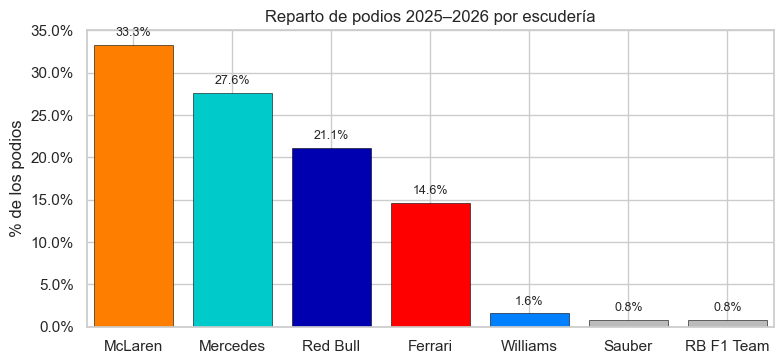

In [24]:
# Evidencia 2: la escudería pesa más que el piloto
grupos = {"Solo piloto": ["grid_c", "drv_exp", "drv_form5", "drv_podrate10", "drv_dnf10", "drv_prev_share", "age"],
          "Solo escudería": ["grid_c", "con_form5", "con_podrate10", "con_dnf10", "con_prev_share"]}
filas = []
for n, cols in grupos.items():
    m = make_pipeline(StandardScaler(), LogisticRegression(C=1, max_iter=5000)).fit(trva[cols], trva.podium)
    r = make_pipeline(StandardScaler(), Ridge(alpha=100)).fit(trva[cols], trva.positionOrder)
    filas.append({"variables": n, "ROC-AUC podio": roc_auc_score(te.podium, m.predict_proba(te[cols])[:, 1]),
                  "R² posición": r2_score(te.positionOrder, r.predict(te[cols]))})
display(pd.DataFrame(filas).set_index("variables"))

# ¿qué tan concentrados están los podios en pocas escuderías?
pod_esc = (te[te.podium == 1].groupby(["constructorId", "escuderia"]).size()
             .div(te.podium.sum()).sort_values(ascending=False).reset_index(name="share"))
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.bar(pod_esc.escuderia, pod_esc.share, color=pod_esc.constructorId.map(color_equipo), edgecolor="black", linewidth=.4)
for i, v in enumerate(pod_esc.share):
    ax.text(i, v + .01, f"{v:.1%}", ha="center", fontsize=9)
ax.set(title="Reparto de podios 2025–2026 por escudería", ylabel="% de los podios")
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
plt.tight_layout(); plt.show()

In [25]:
# Evidencia 3: la élite como anomalía (DBSCAN) + el modelo supervisado subestima a quienes vencen a su auto
ruido = perf[perf.cluster == -1].sort_values("win_rate", ascending=False)
display(ruido[["nombre", "starts", "win_rate", "podium_rate", "dnf_rate", "avg_grid", "avg_gain", "pts_share"]].head(15))
print(f"Pilotos campeones en el ruido: {ruido.win_rate.gt(0.1).sum()} de {perf.win_rate.gt(0.1).sum()} con >10% de victorias")

# residuo = real - predicho (negativo = terminó MEJOR de lo esperado). Con ~40 carreras hay que medir la incertidumbre.
te["residuo"] = te.positionOrder - te.pred_pos
centro_fin = te.loc[te.finished == 1, "residuo"].mean()  # al excluir abandonos, todos quedan "mejor" en promedio

def resumen_residuo(d, centro=0.0):
    g = d.groupby("nombre")["residuo"]
    t = pd.DataFrame({"carreras": g.size(), "residuo_medio": g.mean() - centro, "ee": g.std() / np.sqrt(g.size())})
    t["t"] = t.residuo_medio / t.ee
    t["significativo (|t|>2)"] = t.t.abs() > 2
    return t[t.carreras >= 25].sort_values("residuo_medio")

res = resumen_residuo(te).merge(perf[["nombre", "cluster"]], on="nombre", how="left").set_index("nombre")
res_fin = resumen_residuo(te[te.finished == 1], centro_fin)
print("Todas las carreras:")
display(pd.concat([res.head(5), res.tail(5)]).round(2))
print(f"Solo carreras terminadas (centrado en el promedio de los que terminan, {centro_fin:.2f}):")
display(pd.concat([res_fin.head(5), res_fin.tail(5)]).round(2))
print("Abandonos de Norris en prueba:", int((te[te.nombre == "Lando Norris"].finished == 0).sum()), "de", int((te.nombre == "Lando Norris").sum()))

,nombre,starts,win_rate,podium_rate,dnf_rate,avg_grid,avg_gain,pts_share
9,Max Verstappen,148,0.439,0.709,0.095,3.568,0.963,0.830
28,Andrea Kimi Antonelli,41,0.195,0.415,0.098,6.854,0.541,0.583
0,Lewis Hamilton,147,0.150,0.388,0.061,6.014,1.130,0.588
5,Sergio Pérez,122,0.049,0.254,0.131,9.533,2.066,0.466
2,Kimi Räikkönen,37,0.000,0.000,0.081,16.000,3.147,0.012
12,Lance Stroll,146,0.000,0.014,0.205,14.089,2.328,0.096
18,Alexander Albon,125,0.000,0.016,0.208,12.904,1.424,0.095


Pilotos campeones en el ruido: 3 de 4 con >10% de victorias
Todas las carreras:


,carreras,residuo_medio,ee,t,significativo (|t|>2),cluster
nombre,,,,,,
Max Verstappen,41,-0.770,0.870,-0.890,False,-1
Oliver Bearman,41,-0.710,0.650,-1.090,False,0
Liam Lawson,41,-0.600,0.580,-1.040,False,0
Isack Hadjar,38,-0.460,0.760,-0.600,False,0
Esteban Ocon,41,-0.370,0.500,-0.740,False,0
Lando Norris,41,0.940,0.930,1.000,False,1
Alexander Albon,41,0.980,0.660,1.470,False,-1
Pierre Gasly,41,1.010,0.620,1.620,False,0
Fernando Alonso,41,1.140,0.610,1.870,False,0


Solo carreras terminadas (centrado en el promedio de los que terminan, -0.85):


,carreras,residuo_medio,ee,t,significativo (|t|>2)
nombre,,,,,
Max Verstappen,37,-1.380,0.540,-2.540,True
Oliver Bearman,35,-1.080,0.530,-2.040,True
Liam Lawson,35,-0.700,0.510,-1.390,False
Nico Hülkenberg,33,-0.590,0.660,-0.900,False
Isack Hadjar,34,-0.580,0.650,-0.890,False
Gabriel Bortoleto,34,0.380,0.490,0.780,False
Carlos Sainz,35,0.580,0.510,1.120,False
Pierre Gasly,36,0.850,0.510,1.670,False
Lance Stroll,27,0.890,0.710,1.260,False


Abandonos de Norris en prueba: 5 de 41


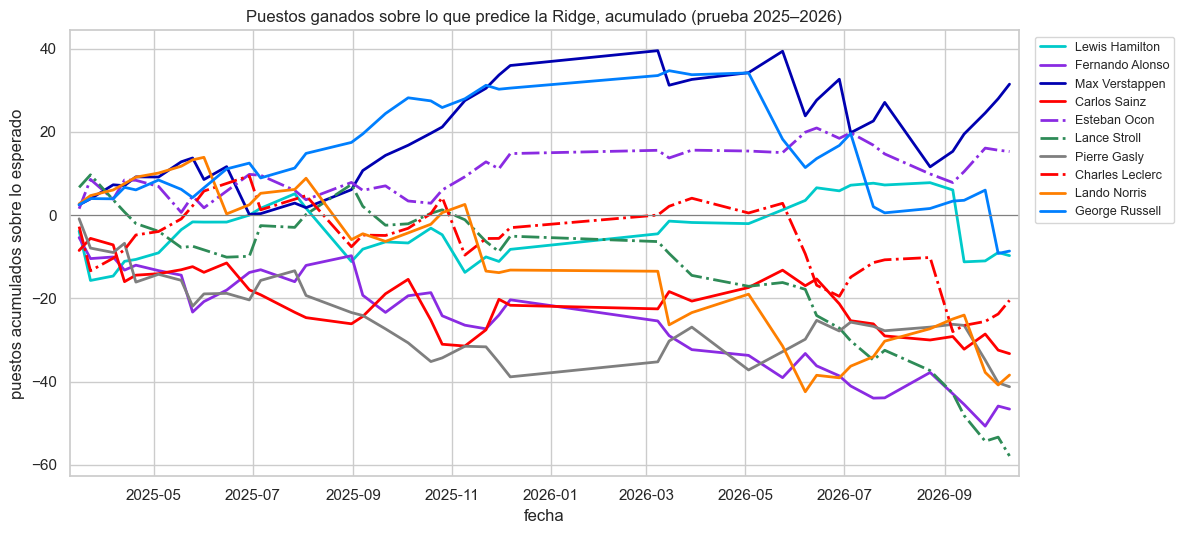

In [26]:
# puestos ganados frente a lo esperado, acumulados carrera a carrera (positivo = rinde sobre su contexto)
te_ord = te.sort_values("date").assign(sobre_esperado=lambda d: d.pred_pos - d.positionOrder)
fig, ax = plt.subplots(figsize=(12, 5.5))
for driver_id, sub in te_ord[te_ord.driverId.isin(DRIVER_C.keys())].groupby("driverId"):
    if len(sub) < 30:
        continue  # pilotos con poca muestra en 2025-2026
    ax.plot(sub.date, sub.sobre_esperado.cumsum(), color=color_piloto(driver_id), ls=estilo_piloto(driver_id),
            lw=2, label=sub.nombre.iloc[0])
ax.axhline(0, c="grey", lw=.8)
ax.set(title="Puestos ganados sobre lo que predice la Ridge, acumulado (prueba 2025–2026)",
       xlabel="fecha", ylabel="puestos acumulados sobre lo esperado")
ax.legend(fontsize=9, loc="upper left", bbox_to_anchor=(1.01, 1))
plt.tight_layout(); plt.show()

> Las cifras exactas citadas abajo provienen de las celdas anteriores. Si se actualizan los datos (por ejemplo, al terminar 2026), deben revisarse.
>
> **Sobre el uso del conjunto de prueba:** todas las decisiones de modelo, parámetros y umbral se tomaron en validación (secciones 3.1, 3.2 y 4). Las comparaciones de esta sección, como "solo grilla" o "solo piloto vs solo escudería", se calculan en prueba **después** de esas decisiones y no cambian ninguna; se usan solo para describir.

### Insight 1 — En la F1 actual, el sábado decide el domingo: la grilla explica casi todo el podio
- **Hallazgo:** un modelo que solo usa la posición de largada predice el podio con **ROC-AUC 0.933**. Agregar forma reciente, confiabilidad y campeonato apenas lo sube a **0.938**. En la posición final, el contexto agrega algo más (R² de 0.418 a 0.444), pero sobre todo evita errores grandes: el RMSE baja de 5.04 a 4.51 mientras el MAE no cambia.
- **Evidencia:** tabla *Solo grilla vs Modelo completo* (prueba 2025–2026), gráfico de % de podio por posición de largada (79 % desde la pole, casi 0 desde el 8º), coeficiente dominante de `grid_c` en la Logística y en la Ridge.
- **Interpretación:** con autos muy confiables (solo 13 % de abandonos) y lo difícil que es adelantar con estos autos, el orden de la clasificación se mantiene en gran medida. Lo que el contexto agrega es corregir casos puntuales, como un auto rápido que larga atrás por una penalización o un error en la clasificación.
- **Implicancia:** para un equipo, **la clasificación del sábado es la palanca principal**. Para un pronóstico, la grilla sola ya es una línea base muy fuerte; un modelo más complejo se justifica para detectar remontadas, no para el caso típico.

### Insight 2 — Cuatro equipos se reparten casi todos los podios, y el auto y el piloto no se pueden separar con resultados
- **Hallazgo:** en 2025–2026, **McLaren (33,3 %), Mercedes (27,6 %), Red Bull (21,1 %) y Ferrari (14,6 %) suman el 96,6 % de los podios**. Las otras 7 escuderías se reparten el 3,4 %. A su vez, un modelo con solo variables del piloto y otro con solo variables de la escudería predicen igual (ROC-AUC 0.938 vs 0.937; R² 0.439 vs 0.445). Lasso, al quedarse con solo 3 variables, conserva la grilla, una del auto (`con_form5`) y una del piloto (`drv_prev_share`).
- **Evidencia:** gráfico de reparto de podios por escudería (colores `TEAM_C`), tabla *Solo piloto vs Solo escudería*, tabla de coeficientes OLS/Ridge/Lasso (sección 4).
- **Interpretación:** a diferencia de eras con un solo equipo dominante, hoy hay un **grupo de cuatro** que compite por el podio y un "muro" que separa a ese grupo del resto de la parrilla. Como los mejores pilotos están en los mejores autos, sus resultados contienen la misma información: con estos datos no se puede atribuir el mérito solo al auto o solo al piloto.
- **Implicancia:** para estar en el podio, primero hay que estar en uno de esos cuatro equipos. Para evaluar a un piloto hay que **descontar el auto**, comparándolo con su compañero o mirando el residuo del modelo (Insight 3), y no contar podios absolutos.

### Insight 3 — Los atípicos son estables, pero "rendir sobre el auto" solo se puede afirmar en pocos casos
- **Hallazgo:** DBSCAN deja como **ruido** a 3 de los 4 pilotos con más de 10 % de victorias (Verstappen, Antonelli y Hamilton), y **Verstappen, Hamilton, Pérez y Stroll son atípicos en todas las variantes** de rasgos y umbrales (sección 5.2). En el modelo supervisado, el residuo medio por piloto en 2025–2026 va de −0,8 a +1,5 puestos, pero **con ~40 carreras casi ninguna diferencia es estadísticamente significativa**:
  - Con todas las carreras, solo **Stroll (+1,45 puestos, t = 2,4)** rinde de forma significativa **peor** de lo que su contexto predice.
  - Considerando solo las carreras que terminaron, para separar el ritmo de la mala suerte, **Verstappen (−1,4, t = −2,5)** y **Bearman (−1,1, t = −2,0)** terminan significativamente **mejor** de lo esperado, y **Tsunoda (+1,3, t = 2,3)** significativamente **peor**.
  - Norris (campeón 2025) tiene residuo positivo con todas las carreras, pero negativo cuando termina. Su "bajo rendimiento" se explica por **5 abandonos en 41 carreras**, no por su ritmo.
- **Evidencia:** tabla de ruido de DBSCAN y prueba de robustez (5.2), gráfico PCA, tablas de residuo con error estándar y t, y gráfico de puestos acumulados sobre lo esperado (colores `DRIVER_C` y estilos `DRIVER_LS`).
- **Interpretación:** el talento de élite no forma un "grupo": es escaso y extremo, y DBSCAN lo detecta de forma estable. En cambio, el ranking de "quién supera a su auto" es **mayormente ruido** con una temporada y media de datos. Las únicas señales confiables son Verstappen y Bearman por arriba, y Stroll y Tsunoda por abajo.
- **Implicancia:** para scouting, el residuo del modelo es útil **solo si se acompaña de su incertidumbre** y se separan los abandonos del ritmo. Bearman, un debutante del bloque central que termina sistemáticamente sobre lo esperado, es el caso a seguir. El resto del ranking no permite conclusiones.

## 7. Conclusiones, limitaciones y recomendaciones

**Conclusiones**
- **P1 (podio):** con información previa a la carrera, la Regresión Logística logra **ROC-AUC 0.938 y PR-AUC 0.730** en 2025–2026. Con umbral 0.5: precision 0.69, recall 0.68 y F1 0.68. Con el umbral 0.30 elegido en validación: recall 0.84 y precision 0.55. El umbral se ajusta según el costo de los falsos positivos.
- **P2 (posición):** la Ridge α=100 obtiene MAE 3.41, RMSE 4.51 y R² 0.444, frente a R² 0.303 de "posición = grilla". Reduce los errores grandes pero no el típico, y su techo lo ponen los abandonos.
- **P3 (perfiles):** DBSCAN (`eps=1.4`, `min_samples=4`) encuentra un bloque mayoritario de mitad/fondo de parrilla (19) y un subgrupo de aspirantes de equipo grande (5), más un **22,6 % de ruido**: la élite ganadora, los remontadores y los pilotos de baja confiabilidad. **Los atípicos son robustos** a cambios de rasgos y umbrales; **la división en dos grupos no lo es**.
- **Robustez:** la validación temporal en 3 años confirma ambas elecciones supervisadas (Logística `C=1` y Ridge α=100), y las probabilidades de podio están razonablemente calibradas (Brier 0.065 vs 0.123 de la tasa base).

**Limitaciones**
- **2026 está incompleto** (17 rondas) y tiene un reglamento nuevo. Las métricas de prueba podrían cambiar al cerrar la temporada.
- No usamos tiempos de clasificación, clima, neumáticos, estrategia de pits ni resultados de las carreras sprint como variables.
- `positionOrder` mezcla a quienes terminaron y a quienes abandonaron. Un modelo en dos etapas (P(abandono) + posición si termina) sería más fiel.
- DBSCAN trabaja con solo 31 pilotos, y tres de sus rasgos son redundantes. Por eso el subgrupo de "aspirantes" depende de la elección de rasgos (sección 5.2).
- El residuo por piloto se calcula con ~40 carreras, así que la mayoría de las diferencias entre pilotos no es significativa (Insight 3).
- Los IDs de los pilotos que debutaron desde 2025, y de Audi y Cadillac, son asignados por nosotros porque Ergast ya no existía. No afectan a los modelos, solo a los colores.

**Recomendaciones / próximos pasos**
1. Agregar la diferencia de tiempo de clasificación frente a la pole y efectos por circuito.
2. Modelar el abandono por separado y combinarlo con la posición esperada.
3. Validar con *rolling origin* (un año de prueba a la vez) y volver a evaluar al terminar 2026.
4. Probar K-Means (justificando `k` con el codo y la silueta) como contraste a DBSCAN.